# Week 6: The Effect Size Files – HydroHype Water Bottle
Ben Dushnitzky

**The claim:** "Carrying our smart water bottle increases average daily water consumption by at least 500 mL compared to standard bottles."

**Measure:** mL of water consumed per day (continuous)

In this notebook I design a study to test the claim, pick a statistical test, look up an effect size from published research, and use a power analysis to find how many people the study needs.

## Study design

- **Who:** healthy adults who don't already use a smart bottle.
- **Groups:** randomly assign people to either the **HydroHype smart bottle** or a **standard bottle** (same size, no tracking or reminders).
- **How long:** 2 weeks. The first few days are a warm-up, then we measure intake over the last 7 days.
- **Outcome:** each person's **average daily water intake in mL** over those 7 days.
- **How we measure it:** both groups keep the same daily drinking log. We can't use the smart bottle's own tracking, because the standard bottle doesn't have it and that would make the comparison unfair.

**Why this design:** random assignment means any difference between the groups should come from the bottle, not from the kind of people who choose to buy a smart bottle. Averaging over 7 days smooths out one-off days (like a hot day or a long workout).

## 1. Null and alternative hypotheses

Let μ_smart be the average daily intake with the HydroHype bottle and μ_standard the average with a standard bottle.

- **Null hypothesis, H0:** μ_smart − μ_standard ≤ 0. The smart bottle does not increase daily water consumption compared to a standard bottle.
- **Alternative hypothesis, H1:** μ_smart − μ_standard > 0. The smart bottle increases daily water consumption compared to a standard bottle.

**Rationale:** the claim only goes in one direction (it says the bottle *increases* intake), so I use a one-sided alternative. The company's specific number, 500 mL, is the effect size I plan the study around in the power analysis (section 4). If the result is significant, we also check whether the estimated difference and its confidence interval actually reach 500 mL.

*Note:* a stricter version would test H0: difference ≤ 500 mL directly. That needs a much bigger sample unless the true effect is well above 500 mL, so I kept the standard version.

## 2. Statistical test

**Welch's two-sample t-test (one-sided).**

Rationale:
- The outcome (mL per day) is **continuous**.
- We compare **two independent groups** (different people in each group).
- Each person's value is an average over 7 days, so with a decent sample size the group means should be close to normal.
- Welch's version **doesn't assume both groups have the same variance**. The smart bottle could make some people drink a lot more and others not change at all, which would make its group more spread out.

If the data turned out very skewed, a Mann-Whitney U test would be a backup.

## 3. Effect size from the literature

To get Cohen's d, I need two things: the **difference** we want to detect and the **standard deviation (SD)** of daily water intake.

**Standard deviation: Nakamura et al. (2020)**
A 12-week randomized trial in 55 healthy Japanese adults. Daily fluid intake at the end of the study was **1444 ± 566 mL** in the control group and **1998 ± 488 mL** in the group told to drink more water. I pool these two SDs to get a realistic spread for daily intake in healthy adults.

**Is 500 mL realistic? Stout et al. (2022)**
A randomized trial of a smart water bottle (HidrateSpark, which tracks intake and sends reminders) in 85 adults with kidney stones. Urine volume went up by **1.37 L** with the smart bottle vs **0.79 L** with dietary advice alone, so about **580 mL more**. This suggests a difference around 500 mL is possible. But those were patients told by their doctor to drink more, so the effect in healthy everyday users is probably smaller.

Because of that, I calculate the sample size for the claimed 500 mL, and also for some smaller differences to see how much the sample size depends on that choice.

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.power import TTestIndPower

# SDs of daily fluid intake from Nakamura et al. (2020)
sd_control = 566
sd_intervention = 488

# Pooled SD (both groups had similar sizes, so a simple average of variances is fine)
pooled_sd = math.sqrt((sd_control**2 + sd_intervention**2) / 2)
print(f"Pooled SD: {pooled_sd:.0f} mL")

# Effect size for the claimed 500 mL difference
claimed_diff = 500
d = claimed_diff / pooled_sd
print(f"Cohen's d for 500 mL: {d:.2f}")

Pooled SD: 528 mL
Cohen's d for 500 mL: 0.95


A d of about 0.95 is a **large** effect by Cohen's rules of thumb (0.2 small, 0.5 medium, 0.8 large). That makes sense: 500 mL is roughly two extra glasses of water a day, which is a big change compared to how much daily intake varies between people.

## 4. Power analysis

Settings:
- **α = 0.05:** the usual 5% chance of a false positive.
- **Power = 0.80:** an 80% chance of detecting the effect if it's real, the common standard.
- **One-sided**, to match H1.
- Equal group sizes.

In [2]:
analysis = TTestIndPower()

n_per_group = analysis.solve_power(effect_size=d, alpha=0.05, power=0.80,
                                   alternative="larger", ratio=1.0)
n_per_group = math.ceil(n_per_group)
print(f"People needed per group: {n_per_group}")
print(f"Total: {n_per_group * 2}")

# Plan for about 20% of people dropping out or not finishing their logs
n_with_dropout = math.ceil(n_per_group / 0.8)
print(f"With 20% dropout: {n_with_dropout} per group, {n_with_dropout * 2} total")

People needed per group: 15
Total: 30
With 20% dropout: 19 per group, 38 total


### What if the real effect is smaller than the company claims?

Companies tend to overstate their results, and the 580 mL from Stout et al. came from patients who were told to drink more. So I also check the sample size for smaller differences, using the same SD.

In [3]:
rows = []
for diff in [500, 400, 300, 250, 200]:
    d_i = diff / pooled_sd
    n_i = math.ceil(analysis.solve_power(effect_size=d_i, alpha=0.05, power=0.80,
                                         alternative="larger"))
    rows.append({"difference (mL)": diff,
                 "Cohen's d": round(d_i, 2),
                 "n per group": n_i,
                 "n per group with 20% dropout": math.ceil(n_i / 0.8)})

table = pd.DataFrame(rows)
table

,difference (mL),Cohen's d,n per group,n per group with 20% dropout
0,500,0.95,15,19
1,400,0.76,23,29
2,300,0.57,40,50
3,250,0.47,56,70
4,200,0.38,88,110


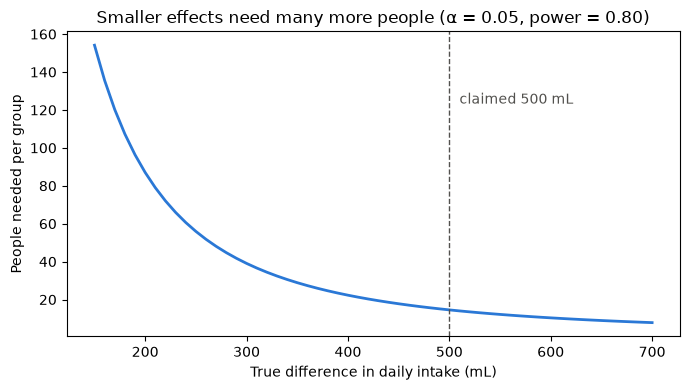

In [4]:
diffs = range(150, 701, 10)
ns = [analysis.solve_power(effect_size=x / pooled_sd, alpha=0.05, power=0.80,
                           alternative="larger") for x in diffs]

plt.figure(figsize=(7, 4))
plt.plot(list(diffs), ns, color="#2a78d6", linewidth=2)
plt.axvline(500, color="#52514e", linestyle="--", linewidth=1)
plt.text(510, max(ns) * 0.8, "claimed 500 mL", color="#52514e")
plt.xlabel("True difference in daily intake (mL)")
plt.ylabel("People needed per group")
plt.title("Smaller effects need many more people (α = 0.05, power = 0.80)")
plt.tight_layout()
plt.show()

## Conclusion and recommendation

- **Required sample size:** if the bottle really adds **500 mL a day** (d ≈ 0.95), we only need about **15 people per group** (30 total), or **19 per group** with dropout.
- But if the real effect is smaller, say **250 mL**, we'd need about **56 per group**.

**My recommendation:** recruit about **70 people per group (140 total)**. That's enough to detect a 250 mL difference even after 20% dropout. It also protects us if the company overstated the effect, which is common, and it's still a realistic size for a 2-week study. With that many people, if the effect really is 500 mL, power will be very close to 100%.

**Rationale summary:**

| Decision | Choice | Why |
|---|---|---|
| Design | Randomized, two groups, 2 weeks | Randomizing removes self-selection bias |
| Outcome | Average daily mL over 7 days | Continuous, smooths out unusual days |
| Hypotheses | One-sided, difference > 0 | The claim only says "increases" |
| Test | Welch's two-sample t-test | Continuous outcome, independent groups, variances may differ |
| SD | 528 mL (Nakamura et al., 2020) | Real daily-intake data from healthy adults |
| Effect size | d = 0.95 for 500 mL; also checked smaller | Claimed value plus a safety margin |
| α, power | 0.05, 0.80 | Standard choices |

## References

- Nakamura, Y., Watanabe, H., Tanaka, A., Yasui, M., Nishihira, J., & Murayama, N. (2020). Effect of Increased Daily Water Intake and Hydration on Health in Japanese Adults. *Nutrients*, 12(4), 1191. https://doi.org/10.3390/nu12041191
- Stout, T. E., Lingeman, J. E., Krambeck, A. E., et al. (2022). A Randomized Trial Evaluating the Use of a Smart Water Bottle to Increase Fluid Intake in Stone Formers. *Journal of Renal Nutrition*, 32(4), 389–395.
- Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences* (2nd ed.). Lawrence Erlbaum Associates.